# FleetGuard: exploratory analysis of NASA C-MAPSS

This notebook explains the data and the reasoning behind FleetGuard's design.
All processing uses the `fleetguard` package, so what is shown here is exactly what the pipeline does.

1. The four subsets at a glance
2. Engine lifetimes and the RUL target
3. Operating regimes: why FD002/FD004 need per-regime normalisation
4. Which sensors carry degradation signal
5. What degradation looks like
6. Results of the trained pipeline (run `python -m fleetguard run-all` first)

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fleetguard.config import SUBSETS, load_config
from fleetguard.data.features import FeaturePipeline
from fleetguard.data.loader import SENSOR_INFO, add_train_rul, load_subset, sensor_label

cfg = load_config()
data = {s: load_subset(cfg.path("raw_data"), s) for s in SUBSETS}
BLUE, ORANGE, AQUA, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6})

## 1. The four subsets

In [2]:
rows = []
for s, d in data.items():
    life = d["train"].groupby("engine_id")["cycle"].max()
    rows.append({
        "subset": s,
        "train engines": d["train"]["engine_id"].nunique(),
        "test engines": d["test"]["engine_id"].nunique(),
        "train rows": len(d["train"]),
        "operating conditions": cfg.subset(s)["operating_conditions"],
        "fault modes": cfg.subset(s)["fault_modes"],
        "lifetime min / median / max": f"{life.min()} / {int(life.median())} / {life.max()}",
        "missing values": int(d["train"].isna().sum().sum()),
    })
pd.DataFrame(rows).set_index("subset")

,train engines,test engines,train rows,operating conditions,fault modes,lifetime min / median / max,missing values
subset,,,,,,,
FD001,100,100,20631,1,1,128 / 199 / 362,0
FD002,260,259,53759,6,1,128 / 199 / 378,0
FD003,100,100,24720,1,2,145 / 220 / 525,0
FD004,249,248,61249,6,2,128 / 234 / 543,0


The data contains no missing values, but a real telemetry feed would. That is why the pipeline still validates
and repairs its input (`fleetguard.data.cleaning`), and the tests feed it deliberately corrupted data.

## 2. Engine lifetimes and the RUL target

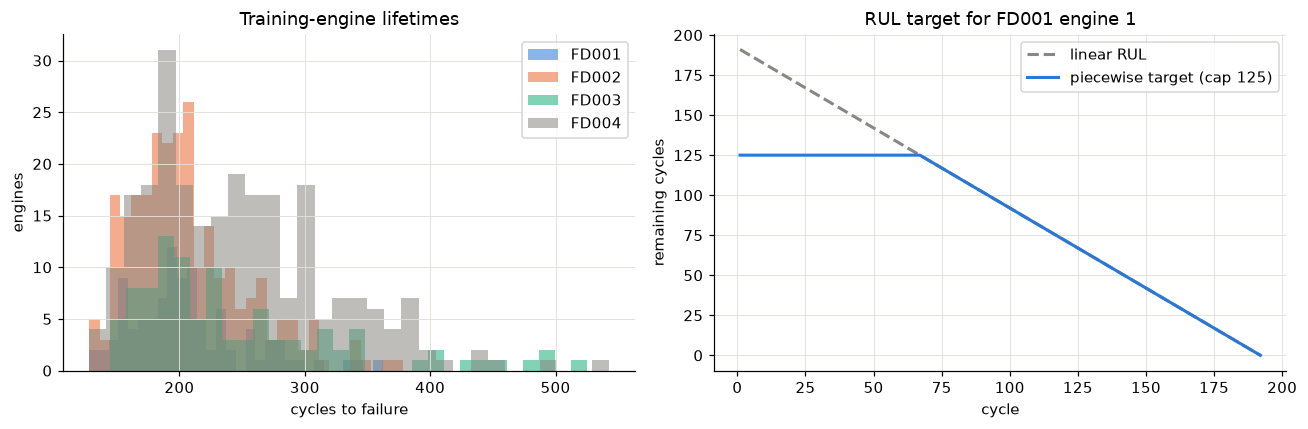

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for s, c in zip(["FD001", "FD002", "FD003", "FD004"], [BLUE, ORANGE, AQUA, MUTED]):
    life = data[s]["train"].groupby("engine_id")["cycle"].max()
    axes[0].hist(life, bins=30, alpha=0.55, color=c, label=s)
axes[0].set(title="Training-engine lifetimes", xlabel="cycles to failure", ylabel="engines")
axes[0].legend()

eng = add_train_rul(data["FD001"]["train"].query("engine_id == 1"), cap=125)
axes[1].plot(eng["cycle"], eng["rul"], color=MUTED, lw=2, ls="--", label="linear RUL")
axes[1].plot(eng["cycle"], eng["rul_capped"], color=BLUE, lw=2, label="piecewise target (cap 125)")
axes[1].set(title="RUL target for FD001 engine 1", xlabel="cycle", ylabel="remaining cycles")
axes[1].legend()
plt.tight_layout()

Early in life an engine shows no degradation, so the model cannot distinguish 250 cycles left from 200 cycles left.
The standard fix, used here, is a **piecewise-linear target capped at 125 cycles**. The cap creates an imbalance:
most rows sit on the plateau and few are near failure.

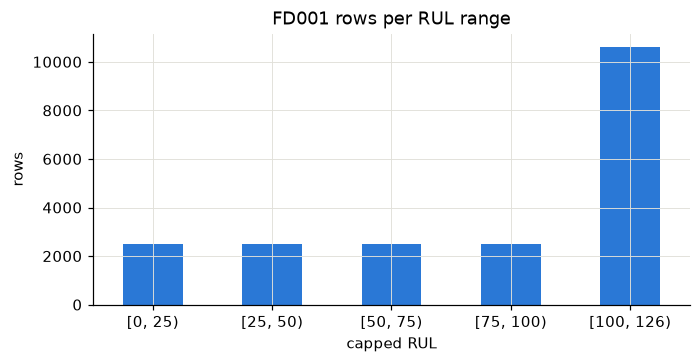

In [4]:
y = add_train_rul(data["FD001"]["train"], cap=125)["rul_capped"]
bins = cfg["training"]["imbalance_bins"]
counts = pd.cut(y, bins=bins, right=False).value_counts().sort_index()
ax = counts.plot.bar(color=BLUE, figsize=(7, 3.2), rot=0, title="FD001 rows per RUL range")
ax.set(xlabel="capped RUL", ylabel="rows");

The near-failure rows are the ones that matter for maintenance, so during training each row is weighted by
`(1 / frequency of its RUL bin) ** 0.5`. The square root keeps the correction mild.

## 3. Operating regimes

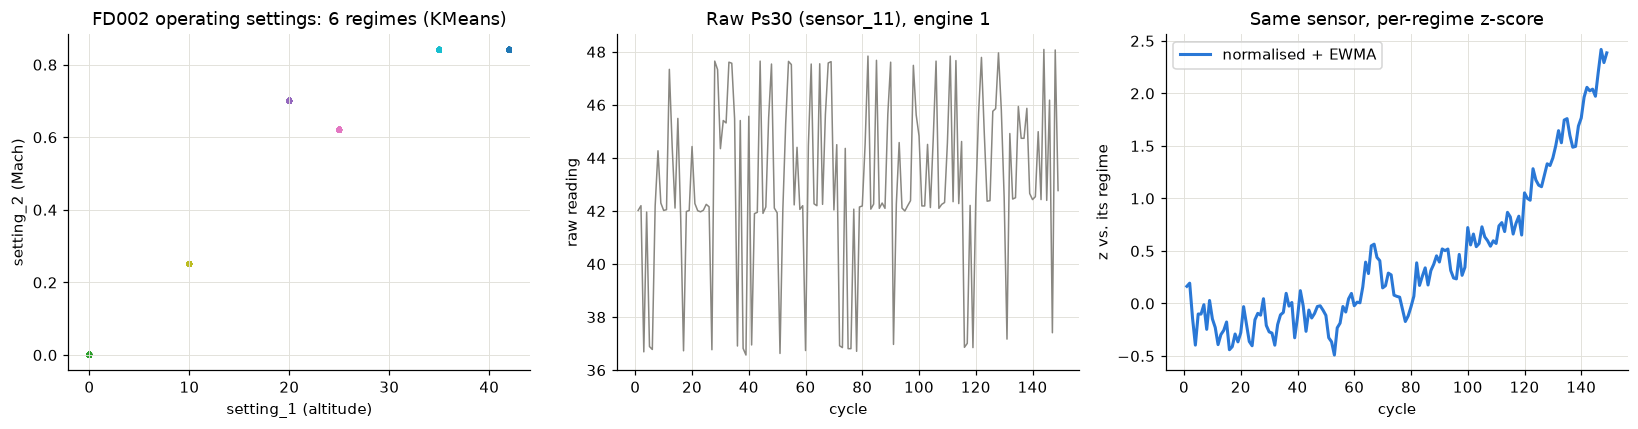

In [5]:
fd2 = data["FD002"]["train"]
fp2 = FeaturePipeline.from_config(cfg, "FD002").fit(fd2)
cond = fp2._conditions(fd2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sample = fd2.assign(condition=cond).sample(4000, random_state=0)
axes[0].scatter(sample["setting_1"], sample["setting_2"], c=sample["condition"], cmap="tab10", s=6)
axes[0].set(title="FD002 operating settings: 6 regimes (KMeans)", xlabel="setting_1 (altitude)", ylabel="setting_2 (Mach)")

eng = fd2[fd2["engine_id"] == 1]
axes[1].plot(eng["cycle"], eng["sensor_11"], color=MUTED, lw=1)
axes[1].set(title="Raw Ps30 (sensor_11), engine 1", xlabel="cycle", ylabel="raw reading")

feats = fp2.transform(eng)
axes[2].plot(feats["cycle"], feats["sensor_11_ewm"], color=BLUE, lw=2, label="normalised + EWMA")
axes[2].set(title="Same sensor, per-regime z-score", xlabel="cycle", ylabel="z vs. its regime")
axes[2].legend()
plt.tight_layout()

In FD002/FD004 the raw reading jumps between flight regimes far more than it changes with wear, which hides the
degradation trend completely. KMeans on the three settings recovers the 6 regimes, and z-scoring every sensor
*within its regime* makes the slow upward wear trend visible. FD001/FD003 have a single regime, so the same code
reduces to a global z-score.

## 4. Which sensors carry degradation signal

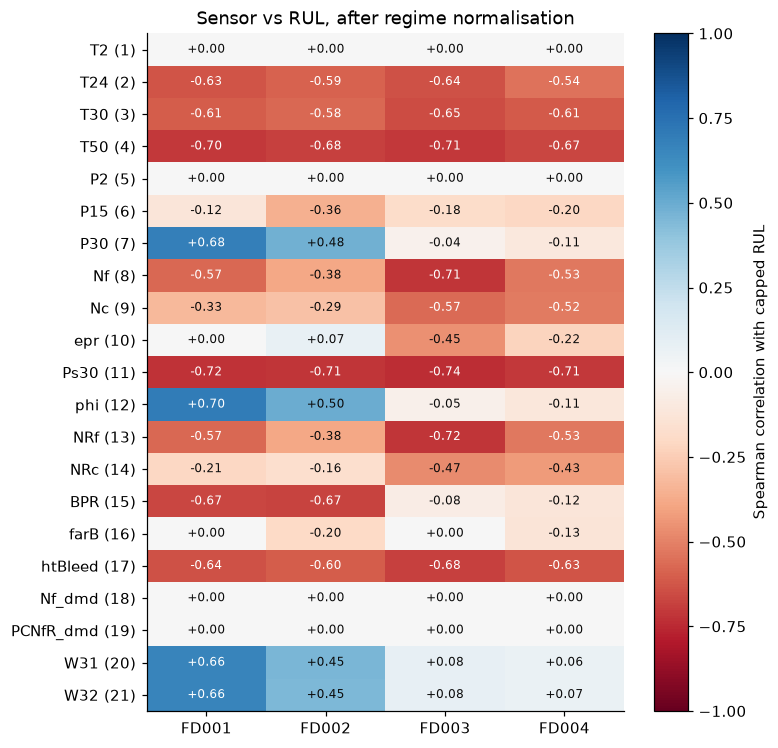

In [6]:
corr = {}
for s in SUBSETS:
    fp = FeaturePipeline.from_config(cfg, s).fit(data[s]["train"])
    corr[s] = fp.summary()["sensor_spearman_rul"]
corr = pd.DataFrame(corr)
corr.index = [f"{SENSOR_INFO[i][0]} ({i.split('_')[1]})" for i in corr.index]

fig, ax = plt.subplots(figsize=(7, 8))
im = ax.imshow(corr.values, cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(4), corr.columns)
ax.set_yticks(range(len(corr)), corr.index)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]):
        ax.text(j, i, f"{corr.values[i, j]:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.values[i, j]) > 0.5 else "#0b0b0b")
ax.grid(False)
fig.colorbar(im, ax=ax, label="Spearman correlation with capped RUL")
ax.set_title("Sensor vs RUL, after regime normalisation");

Sensors with |ρ| < 0.05, or that are constant within every regime, are dropped automatically from the training data
(for FD001 these are exactly the 7 flat sensors documented by NASA). Temperatures (T24, T30, T50), HPC pressure
(Ps30) and bleed enthalpy rise towards failure, while fuel-flow ratio (phi) and HPC outlet pressure (P30) fall.

## 5. What degradation looks like

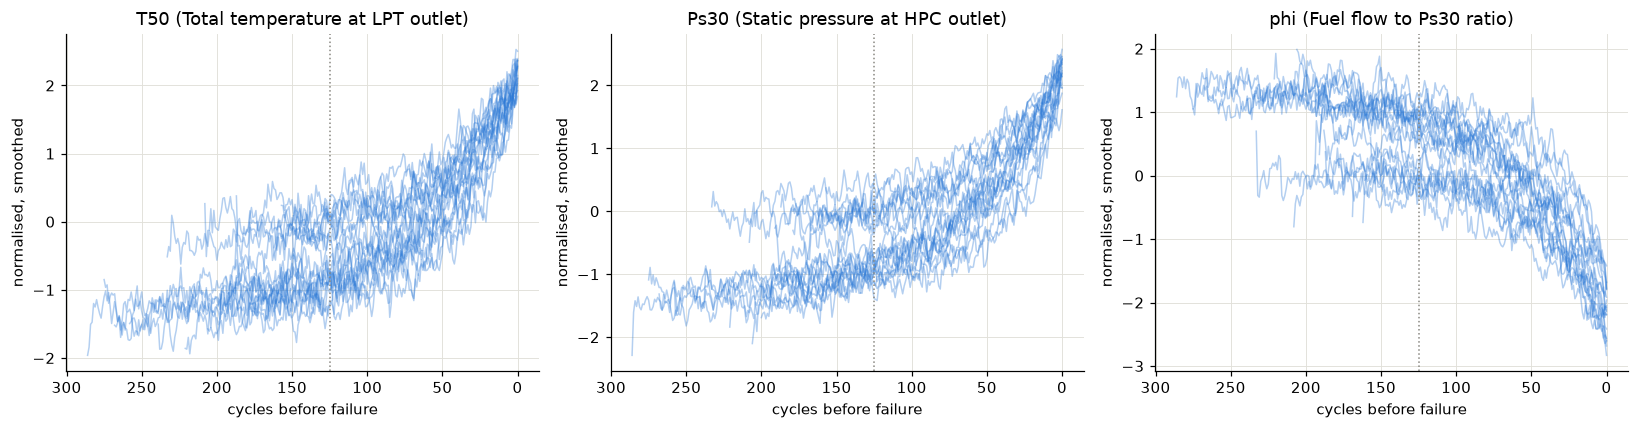

In [7]:
fd1 = add_train_rul(data["FD001"]["train"], cap=None)
fp1 = FeaturePipeline.from_config(cfg, "FD001").fit(fd1)
f1 = fp1.transform(fd1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharex=True)
for ax, s in zip(axes, ["sensor_4", "sensor_11", "sensor_12"]):
    for e in range(1, 21):
        g = f1[f1["engine_id"] == e]
        ax.plot(g["rul"], g[f"{s}_ewm"], color=BLUE, alpha=0.35, lw=1)
    ax.axvline(125, color=MUTED, ls=":", lw=1)
    ax.set(title=sensor_label(s), xlabel="cycles before failure", ylabel="normalised, smoothed")
axes[0].invert_xaxis()
plt.tight_layout()

For 20 engines, each sensor stays flat for most of the engine's life and then bends sharply over the last
~100 cycles. This is why the target is capped and why trend features (rolling slope, drift from the engine's own
first cycles) help. It also supports the anomaly detectors: they learn the flat "healthy" region and flag the departure from it.

## 6. Results of the trained pipeline

In [8]:
summary_path = cfg.path("outputs") / "summary.json"
if summary_path.exists():
    summary = json.loads(summary_path.read_text())
    display(pd.DataFrame({s: r["metrics"] for s, r in summary.items()}).T.round(3))
else:
    print("Run `python -m fleetguard run-all` to produce results.")

,test_rmse,test_mae,test_nasa_score,test_uncapped_rmse,test_interval_coverage,agent_recall_near_failure,agent_false_alarm_rate,agent_missed_critical
FD001,11.442,8.294,170.519,12.796,0.750,1.000,0.000,0.0
FD002,11.150,7.772,531.401,24.042,0.799,0.984,0.000,0.0
FD003,10.244,6.708,218.339,12.091,0.800,1.000,0.000,0.0
FD004,11.630,7.540,652.376,24.831,0.786,1.000,0.009,0.0


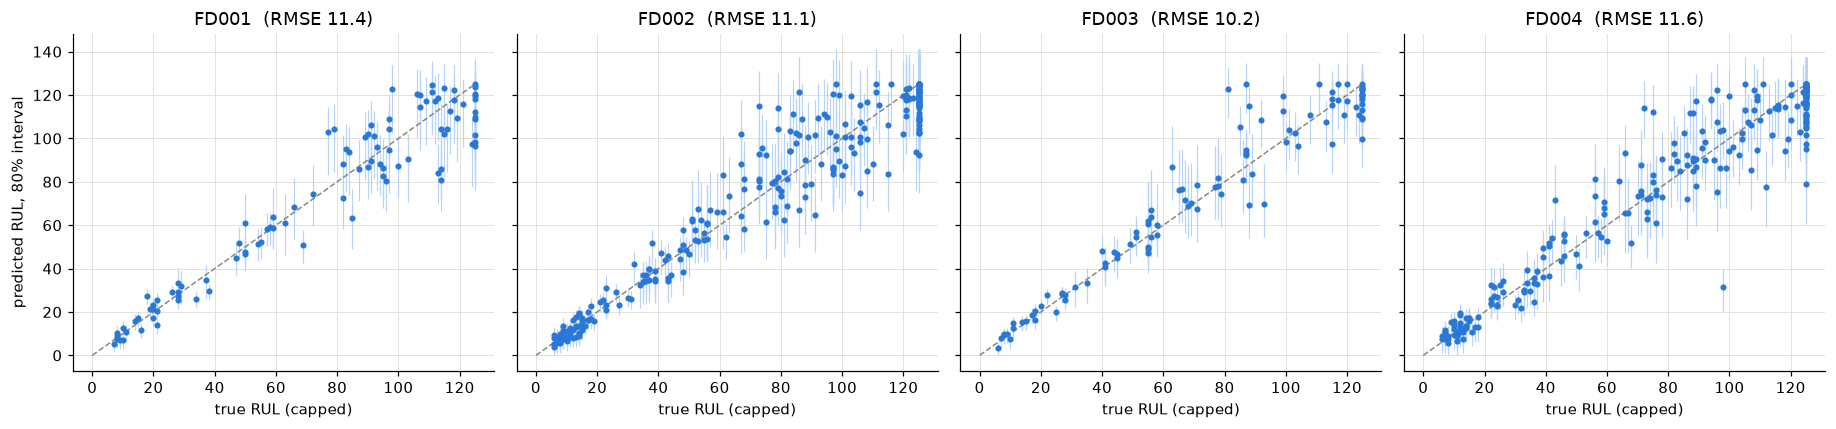

In [9]:
paths = {s: cfg.path("outputs") / s / "evaluation" / "test_predictions.csv" for s in SUBSETS}
avail = {s: pd.read_csv(p) for s, p in paths.items() if p.exists()}
if avail:
    fig, axes = plt.subplots(1, len(avail), figsize=(4.2 * len(avail), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (s, tp) in zip(axes, avail.items()):
        t = tp["true_rul"].clip(upper=125)
        ax.errorbar(t, tp["rul_pred"], yerr=[tp["rul_pred"] - tp["rul_lower"], tp["rul_upper"] - tp["rul_pred"]],
                    fmt="o", ms=3, color=BLUE, ecolor="#b7d3f6", elinewidth=0.8)
        ax.plot([0, 125], [0, 125], color=MUTED, ls="--", lw=1)
        rmse = np.sqrt(np.mean((tp["rul_pred"] - t) ** 2))
        ax.set(title=f"{s}  (RMSE {rmse:.1f})", xlabel="true RUL (capped)")
    axes[0].set_ylabel("predicted RUL, 80% interval")
    plt.tight_layout()

Predictions follow the diagonal closely near failure, where it matters most. Far from failure the model
deliberately saturates at the cap. The vertical bars are the conformal 80% intervals, which are narrower near
failure and wider on the plateau.

**Next:** `streamlit run dashboard/app.py` for the work orders and engine-level views, and `docs/DESIGN.md`
for the design decisions.